# S6E11 — Independent ML-Only Fraud Detection Research Pipeline

**Competition:** Kaggle Playground Series S6E11 (`playground-series-s6e11`) — Binary Classification (`ROC AUC`)  
**Methodology:** 100% Standalone, Strict Conventional Supervised ML (Zero LLMs, zero pretrained embeddings, zero external participants' OOF/test files, zero post-hoc blending).

### Architectural Overview (4 Complementary Families, 7 Models)
1. **High-Dimensional Exact & Digit-Trie Generalized Linear Models (`02e_SpGLM`, `02f_DeGLM`):**
   - Exploit first-principles EDA findings: standard quantile bins smooth over sharp non-monotonic discrete risk spikes (`customer_age`, `merchant_risk_score`, `velocity_score`) and statistically significant cent/decimal artifacts (`amount_usd` cents $\chi^2$, $p \ll 10^{-3}$).
   - Combines 10-knot cubic B-splines over smooth continuous variables with selective digit-trie prefix/suffix sparse OHE (block-scaled L2 Logistic) and 3-seed nested empirical-Bayes log-odds target encoding (`m=[10, 50]`).
2. **Strictly Nested-OOF GLM-Offset Shallow Residual GBDTs (`03a_OffLGB`, `03b_OffXGB`, `03c_OffCAT`):**
   - Uses a strictly **nested out-of-fold** 50/50 GLM logit blend as `init_score`/`base_margin`/`baseline` inside each outer fold, preventing in-sample offset memorization while focusing ultra-shallow trees (`4 leaves` extra-trees LightGBM, `lossguide 4 leaves` XGBoost, `depth=4 SymmetricTree` CatBoost) strictly on non-additive residual interactions.
3. **Standalone High-Bin Shallow GBDT (`03d_StXGB`):**
   - Depth-2 `max_bin=1024` XGBoost over continuous features, frequencies, and quantile interaction pairs (`m=20`), anchoring standalone tree boundaries without GLM offsets.
4. **Zero-TE High-Resolution Explainable Boosting Machine (`04_EBM`):**
   - Cyclic GA2M (`max_bins=1024`, top 25 pairwise shape functions, zero target encoding) capturing orthogonal 1D discrete spikes and pairwise interactions.
5. **Residual-Decomposed Non-Negative Logit Meta-Learner (`ResDecomp_NonNeg`):**
   - Explicitly parameterizes offset-boosted models as $\Delta_m = z_m - z_{\text{b50}}$ before non-negative L2 logistic regression (`logit_eps = 1e-10`) inside outer-fold-blind nested CV, resolving convex simplex collinearity traps.


In [1]:
import gc
import importlib.metadata
import json
import os
import platform
import random
import time
from pathlib import Path

import matplotlib
if not os.environ.get("MPLBACKEND"):
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
from catboost import CatBoostClassifier, Pool
from interpret.glassbox import ExplainableBoostingClassifier
from lightgbm import LGBMClassifier
from scipy import sparse, stats
from scipy.optimize import minimize
from scipy.special import expit, log_expit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.preprocessing import SplineTransformer, StandardScaler
from xgboost import XGBClassifier

# Runtime execution mode: SMOKE_TEST=1 validates the entire pipeline rapidly;
# default SMOKE_TEST=0 runs full 10-fold training on 100% of competition rows.
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

GLOBAL_SEED = 2026
np.random.seed(GLOBAL_SEED)
random.seed(GLOBAL_SEED)

if SMOKE_TEST:
    N_FOLDS = 2
    INNER_OFFSET_FOLDS = 2
    SEEDS = [42]
    LGB_N_EST = 60
    XGB_N_EST = 50
    CAT_N_EST = 80
    STXGB_N_EST = 150
    EBM_MAX_BINS = 256
    EBM_INTERACTIONS = 5
    META_INNER_FOLDS = 3
    SMOKE_TR_N = 25000
    SMOKE_TE_N = 5000
else:
    N_FOLDS = 10
    INNER_OFFSET_FOLDS = 3
    SEEDS = [42, 101, 202]
    LGB_N_EST = 297
    XGB_N_EST = 174
    CAT_N_EST = 429
    STXGB_N_EST = 2346
    EBM_MAX_BINS = 1024
    EBM_INTERACTIONS = 25
    META_INNER_FOLDS = 5
    SMOKE_TR_N = None
    SMOKE_TE_N = None

LOCKED_MODELS = [
    "02e_SpGLM",
    "02f_DeGLM",
    "03a_OffLGB",
    "03b_OffXGB",
    "03c_OffCAT",
    "03d_StXGB",
    "04_EBM",
]
LOGIT_EPS = 1e-10
CPU_THREADS = min(8, os.cpu_count() or 4)

# Resolve official competition CSV directory without hardcoding machine paths
DATA_CANDIDATES = []
_data_ovr = os.environ.get("DATA_DIR_OVERRIDE", "").strip()
if _data_ovr:
    DATA_CANDIDATES.append(Path(_data_ovr))
DATA_CANDIDATES.extend([
    Path("../data"),
    Path("data"),
    Path("/kaggle/input/playground-series-s6e11"),
    Path("/kaggle/input/competitions/playground-series-s6e11"),
])
DATA_DIR = next(
    (p for p in DATA_CANDIDATES if (p / "train.csv").exists() and (p / "test.csv").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate competition CSVs (train.csv, test.csv) in standard search paths: "
        + ", ".join(str(p) for p in DATA_CANDIDATES)
    )

OUT_OVERRIDE = os.environ.get("OUT_DIR_OVERRIDE", "").strip()
if OUT_OVERRIDE:
    OUT_DIR = Path(OUT_OVERRIDE)
elif Path("../data/train.csv").exists():
    OUT_DIR = Path(".")
elif Path("data/train.csv").exists():
    OUT_DIR = Path("independent_kaggle_research")
else:
    OUT_DIR = Path(".")

OUT_DIR.mkdir(parents=True, exist_ok=True)
ART_DIR = OUT_DIR / "artifacts"
ART_DIR.mkdir(parents=True, exist_ok=True)


def detect_gpu_backends():
    """Probe CUDA availability safely with a minimal 8-row binary smoke fit."""
    X_tiny = np.array(
        [[0.1, 1.0], [1.2, 0.3], [0.2, 0.9], [1.5, 0.1],
         [0.3, 1.1], [1.4, 0.2], [0.0, 0.8], [1.3, 0.4]],
        dtype=np.float32,
    )
    y_tiny = np.array([0, 1, 0, 1, 0, 1, 0, 1], dtype=np.int32)
    xgb_dev = "cpu"
    try:
        m = XGBClassifier(n_estimators=2, max_depth=2, tree_method="hist", device="cuda")
        m.fit(X_tiny, y_tiny, verbose=False)
        xgb_dev = "cuda"
    except Exception:
        xgb_dev = "cpu"

    cat_task = "CPU"
    try:
        c = CatBoostClassifier(iterations=2, depth=2, task_type="GPU", allow_writing_files=False, verbose=0)
        c.fit(X_tiny, y_tiny, verbose=False)
        cat_task = "GPU"
    except Exception:
        cat_task = "CPU"
    return xgb_dev, cat_task


XGB_DEVICE, CAT_TASK_TYPE = detect_gpu_backends()


def current_ram_gb():
    return float(psutil.Process().memory_info().rss / (1024 ** 3))


PKG_LIST = ["numpy", "pandas", "scipy", "scikit-learn", "lightgbm", "xgboost", "catboost", "interpret"]
ENV_INFO = {"python": platform.python_version()}
for pkg in PKG_LIST:
    try:
        ENV_INFO[pkg] = importlib.metadata.version(pkg)
    except Exception:
        ENV_INFO[pkg] = "unavailable"

print(f"Mode        : {'SMOKE_TEST' if SMOKE_TEST else 'FULL_CONFIRM10'}")
print(f"DATA_DIR    : {DATA_DIR.resolve()}")
print(f"OUT_DIR     : {OUT_DIR.resolve()}")
print(f"Config      : folds={N_FOLDS}, inner_off={INNER_OFFSET_FOLDS}, seeds={SEEDS}, threads={CPU_THREADS}")
print(f"Accelerators: XGB_DEVICE={XGB_DEVICE}, CAT_TASK_TYPE={CAT_TASK_TYPE}")
print(f"Packages    : {ENV_INFO}")


Mode        : FULL_CONFIRM10
DATA_DIR    : C:\Users\LaptopK1\Downloads\Code\Predicting Credit Card Fraud\data
OUT_DIR     : C:\Users\LaptopK1\Downloads\Code\Predicting Credit Card Fraud\independent_kaggle_research
Config      : folds=10, inner_off=3, seeds=[42, 101, 202], threads=8
Accelerators: XGB_DEVICE=cuda, CAT_TASK_TYPE=GPU
Packages    : {'python': '3.13.12', 'numpy': '2.5.5', 'pandas': '3.1.1', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'xgboost': '3.4.1', 'catboost': '1.2.10', 'interpret': '0.7.8'}


## 1. First-Principles Data Integrity & Live EDA Verification

All data checks, distributional statistics, and exact-value artifact verifications below run dynamically directly on `train.csv` and `test.csv`.

Loaded train=(699960, 26), test=(299984, 25) in 1.22s | fraud_rate=0.016700 (11689/699960) | missing=(tr:0, te:0) | feat_dups=0
EDA Signal Check: amount_usd cents chi2=370.68 (p=4.99e-33) | cents=.00 rate=0.0209, cents=.49 rate=0.0249 | velocity_score integer rate=0.0110 vs non-integer=0.0178


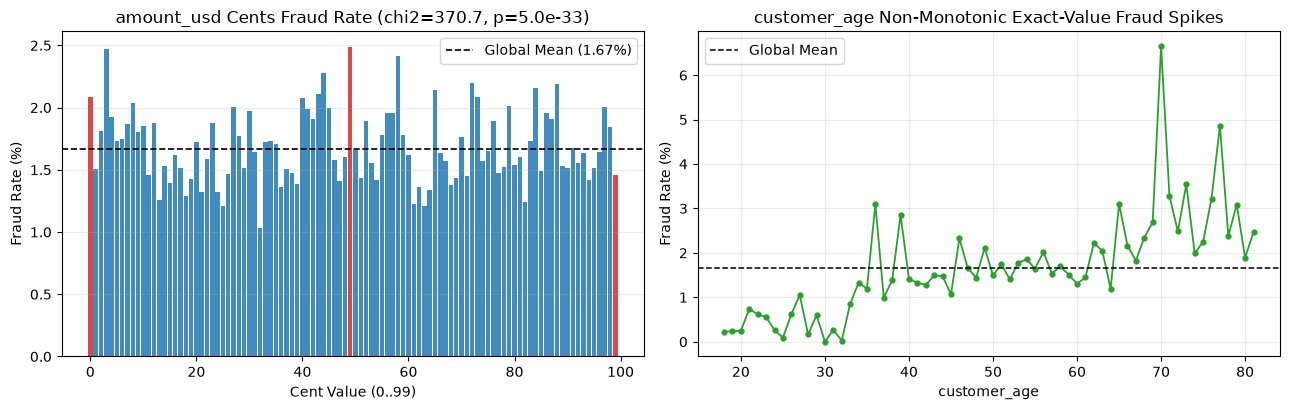

In [2]:
t0_load = time.perf_counter()
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

if SMOKE_TEST:
    splitter = StratifiedShuffleSplit(n_splits=1, train_size=SMOKE_TR_N, random_state=GLOBAL_SEED)
    keep_idx, _ = next(splitter.split(train_df, train_df["is_fraud"]))
    keep_idx = np.sort(keep_idx)
    train_df = train_df.iloc[keep_idx].reset_index(drop=True)
    test_df = test_df.iloc[:SMOKE_TE_N].reset_index(drop=True)

y = train_df["is_fraud"].astype(np.int8).to_numpy()
n_missing_tr = int(train_df.isna().sum().sum())
n_missing_te = int(test_df.isna().sum().sum())
feat_cols = [c for c in test_df.columns if c != "id"]
n_dup_tr = int(train_df.duplicated(subset=feat_cols).sum())

print(
    f"Loaded train={train_df.shape}, test={test_df.shape} in {time.perf_counter() - t0_load:.2f}s | "
    f"fraud_rate={y.mean():.6f} ({int(y.sum())}/{len(y)}) | "
    f"missing=(tr:{n_missing_tr}, te:{n_missing_te}) | feat_dups={n_dup_tr}"
)
assert n_missing_tr == 0 and n_missing_te == 0, "Unexpected missing values"

# Compute first-principles cent & integer artifact diagnostics strictly on train_df
amt_cents = np.rint(train_df["amount_usd"].to_numpy(dtype=np.float64) * 100.0).astype(np.int64) % 100
cnt_c = np.bincount(amt_cents, minlength=100).astype(np.float64)
pos_c = np.bincount(amt_cents, weights=y, minlength=100).astype(np.float64)
rate_c = pos_c / np.maximum(cnt_c, 1.0)
p_base = float(y.mean())
expected_pos = cnt_c * p_base
expected_neg = cnt_c * (1.0 - p_base)
valid_chi = (expected_pos >= 5.0) & (expected_neg >= 5.0)
chi2_cents = float(
    np.sum((pos_c[valid_chi] - expected_pos[valid_chi]) ** 2 / expected_pos[valid_chi])
    + np.sum(((cnt_c[valid_chi] - pos_c[valid_chi]) - expected_neg[valid_chi]) ** 2 / expected_neg[valid_chi])
)
p_chi2_cents = float(stats.chi2.sf(chi2_cents, df=max(int(valid_chi.sum()) - 1, 1)))

vel_vals = train_df["velocity_score"].to_numpy(dtype=np.float64)
vel_sc10 = np.rint(vel_vals * 10.0).astype(np.int64)
vel_is_int = (vel_sc10 % 10) == 0
vel_int_rate = float(y[vel_is_int].mean())
vel_frac_rate = float(y[~vel_is_int].mean())

age_vals = train_df["customer_age"].to_numpy(dtype=np.int64)
age_df = (
    pd.DataFrame({"age": age_vals, "y": y})
    .groupby("age", as_index=False)
    .agg(n=("y", "count"), fraud_rate=("y", "mean"))
)
age_df = age_df[age_df["n"] >= 30].sort_values("age")

print(
    f"EDA Signal Check: amount_usd cents chi2={chi2_cents:.2f} (p={p_chi2_cents:.2e}) | "
    f"cents=.00 rate={rate_c[0]:.4f}, cents=.49 rate={rate_c[49]:.4f} | "
    f"velocity_score integer rate={vel_int_rate:.4f} vs non-integer={vel_frac_rate:.4f}"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
bar_colors = ["#d62728" if i in (0, 49, 99) else "#1f77b4" for i in range(100)]
ax.bar(np.arange(100), rate_c * 100.0, color=bar_colors, width=0.85, alpha=0.85)
ax.axhline(p_base * 100.0, color="black", linestyle="--", linewidth=1.2, label=f"Global Mean ({p_base*100:.2f}%)")
ax.set_title(f"amount_usd Cents Fraud Rate (chi2={chi2_cents:.1f}, p={p_chi2_cents:.1e})")
ax.set_xlabel("Cent Value (0..99)")
ax.set_ylabel("Fraud Rate (%)")
ax.legend(frameon=True)
ax.grid(axis="y", alpha=0.25)

ax2 = axes[1]
ax2.plot(age_df["age"], age_df["fraud_rate"] * 100.0, marker="o", markersize=3.5, linewidth=1.3, color="#2ca02c")
ax2.axhline(p_base * 100.0, color="black", linestyle="--", linewidth=1.1, label="Global Mean")
ax2.set_title("customer_age Non-Monotonic Exact-Value Fraud Spikes")
ax2.set_xlabel("customer_age")
ax2.set_ylabel("Fraud Rate (%)")
ax2.legend(frameon=True)
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()
plt.close(fig)


## 2. Inductive Feature Engineering: Arithmetic Digit-Trie & Nested Log-Odds Encoder

Every transformation in `build_digit_trie_views` and `FastFoldInductiveEncoder` is strictly inductive: numeric/digit keys are deterministic row functions, while spline knots, quantile interaction cutpoints, minimum-frequency vocabularies, empirical frequencies, and multi-scale smoothed target encodings are fit strictly inside each fold's training split (`tr_idx`).

In [3]:
CAT_COLS = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
BOOL_COLS = [
    "is_foreign_transaction", "is_new_merchant", "used_vpn",
    "ip_country_mismatch", "billing_shipping_mismatch", "is_ai_generated_scam_attempt",
]
FLOATS_2DEC = ["amount_usd", "account_balance_usd", "hours_since_last_txn", "distance_from_home_km"]
FLOATS_1DEC = ["velocity_score", "merchant_risk_score"]
ALL_FLOATS = FLOATS_2DEC + FLOATS_1DEC
INT_NUM_COLS = [
    "txn_count_last_24h", "card_age_months", "customer_age",
    "cvv_retry_count", "time_of_day_hour", "day_of_week", "prior_disputes",
]
ALL_NUM_COLS = ALL_FLOATS + INT_NUM_COLS

# Continuous features eligible for cubic splines (excluding binary/sin-cos/low-cardinality ints)
SPLINE_CONT_COLS = [
    "log1p_amount_usd", "log1p_account_balance_usd", "log1p_hours_since_last_txn",
    "log1p_distance_from_home_km", "velocity_score", "merchant_risk_score",
    "customer_age", "card_age_months", "time_of_day_hour",
    "amount_to_balance_ratio", "amount_per_txn24", "velocity_per_hour", "risk_x_velocity",
]

# Selective exact-value & digit-trie targets (excludes smooth negative controls)
EXACT_POSITIVE_COLS = [
    "customer_age", "merchant_risk_score", "velocity_score",
    "hours_since_last_txn", "account_balance_usd", "amount_usd",
    "txn_count_last_24h", "cvv_retry_count",
]


def _leading_digits_vec(int_arr: np.ndarray):
    a = np.abs(int_arr).astype(np.int64)
    n_dig = np.where(a == 0, 1, np.floor(np.log10(np.maximum(a, 1))).astype(np.int64) + 1)
    d1 = a // (10 ** np.maximum(n_dig - 1, 0))
    d2 = np.where(n_dig >= 2, a // (10 ** np.maximum(n_dig - 2, 0)), a) + n_dig * 100
    d3 = np.where(n_dig >= 3, a // (10 ** np.maximum(n_dig - 3, 0)), a) + n_dig * 1000
    return n_dig.astype(np.int32), d1.astype(np.int32), d2.astype(np.int32), d3.astype(np.int32)


def build_digit_trie_views(df: pd.DataFrame, selective_digits: bool = True):
    """
    100% inductive row-wise features + Arithmetic Digit-Trie Prefix & Suffix Hierarchy.
    Strictly deterministic per single row: zero target info, zero cross-row or test dependence.
    """
    n = len(df)
    num_dict = {}
    key_dict = {}

    for c in CAT_COLS:
        key_dict[f"cat_{c}"] = df[c].astype(str)
    for c in BOOL_COLS:
        b = df[c].astype(np.int8).to_numpy()
        num_dict[c] = b.astype(np.float32)
        key_dict[f"bool_{c}"] = b.astype(np.int32)

    bool_mat = np.column_stack([df[c].astype(np.int32).to_numpy() for c in BOOL_COLS])
    num_dict["risk_flag_sum"] = bool_mat.sum(axis=1).astype(np.float32)
    b6 = np.zeros(n, dtype=np.int32)
    for bit_i in range(len(BOOL_COLS)):
        b6 += (bool_mat[:, bit_i] << bit_i)
    key_dict["pair_bool6"] = b6

    for c in ALL_NUM_COLS:
        v = df[c].to_numpy(dtype=np.float32)
        num_dict[c] = v
        if v.min() >= 0 and c in ALL_FLOATS + ["txn_count_last_24h"]:
            num_dict[f"log1p_{c}"] = np.log1p(np.maximum(v, 0.0)).astype(np.float32)

    amt = df["amount_usd"].to_numpy(dtype=np.float32)
    bal = df["account_balance_usd"].to_numpy(dtype=np.float32)
    txn24 = df["txn_count_last_24h"].to_numpy(dtype=np.float32)
    hrs = df["hours_since_last_txn"].to_numpy(dtype=np.float32)
    vel = df["velocity_score"].to_numpy(dtype=np.float32)
    mrs = df["merchant_risk_score"].to_numpy(dtype=np.float32)

    num_dict["amount_to_balance_ratio"] = np.log1p(amt / (np.maximum(bal, 0.0) + 1.0)).astype(np.float32)
    num_dict["amount_per_txn24"] = np.log1p(amt / (np.maximum(txn24, 0.0) + 1.0)).astype(np.float32)
    num_dict["velocity_per_hour"] = np.log1p(vel / (np.maximum(hrs, 0.0) + 0.1)).astype(np.float32)
    num_dict["risk_x_velocity"] = (mrs * vel / 100.0).astype(np.float32)

    ang_h = 2.0 * np.pi * df["time_of_day_hour"].to_numpy(dtype=np.float32) / 24.0
    num_dict["hour_sin"] = np.sin(ang_h).astype(np.float32)
    num_dict["hour_cos"] = np.cos(ang_h).astype(np.float32)
    ang_d = 2.0 * np.pi * df["day_of_week"].to_numpy(dtype=np.float32) / 7.0
    num_dict["dow_sin"] = np.sin(ang_d).astype(np.float32)
    num_dict["dow_cos"] = np.cos(ang_d).astype(np.float32)

    for c in FLOATS_2DEC:
        v = df[c].to_numpy(dtype=np.float64)
        sc100 = np.rint(v * 100.0).astype(np.int64)
        int_p = sc100 // 100
        cents = sc100 % 100
        tenths = (sc100 // 10) % 10
        hundredths = sc100 % 10
        is_int = (cents == 0).astype(np.int8)

        num_dict[f"cents_{c}"] = cents.astype(np.float32)
        num_dict[f"tenths_{c}"] = tenths.astype(np.float32)
        num_dict[f"is_int_{c}"] = is_int.astype(np.float32)

        if c in EXACT_POSITIVE_COLS:
            key_dict[f"exact_{c}"] = sc100
            key_dict[f"pref1_{c}"] = sc100 // 10
            key_dict[f"int_{c}"] = int_p
            key_dict[f"ten_{c}"] = int_p // 10
            key_dict[f"hund_{c}"] = int_p // 100
            key_dict[f"thou_{c}"] = int_p // 1000
        ndig, ld1, ld2, ld3 = _leading_digits_vec(int_p)
        key_dict[f"ndig_{c}"] = ndig
        key_dict[f"ld1_{c}"] = ld1
        key_dict[f"is_int_{c}"] = is_int.astype(np.int32)
        if not selective_digits or c in EXACT_POSITIVE_COLS:
            key_dict[f"ld2_{c}"] = ld2
            key_dict[f"ld3_{c}"] = ld3
            key_dict[f"cents_{c}"] = cents.astype(np.int32)
            key_dict[f"suf3_{c}"] = (sc100 % 1000).astype(np.int32)
            key_dict[f"suf4_{c}"] = (sc100 % 10000).astype(np.int32)
            key_dict[f"tenths_{c}"] = tenths.astype(np.int32)
            key_dict[f"hundredths_{c}"] = hundredths.astype(np.int32)
            key_dict[f"mod10_{c}"] = (int_p % 10).astype(np.int32)
            key_dict[f"mod100_{c}"] = (int_p % 100).astype(np.int32)

    for c in FLOATS_1DEC:
        v = df[c].to_numpy(dtype=np.float64)
        sc10 = np.rint(v * 10.0).astype(np.int64)
        int_p = sc10 // 10
        tenths = sc10 % 10
        is_int = (tenths == 0).astype(np.int8)

        num_dict[f"tenths_{c}"] = tenths.astype(np.float32)
        num_dict[f"is_int_{c}"] = is_int.astype(np.float32)

        key_dict[f"exact_{c}"] = sc10
        key_dict[f"int_{c}"] = int_p
        key_dict[f"ten_{c}"] = int_p // 10
        ndig, ld1, ld2, _ = _leading_digits_vec(int_p)
        key_dict[f"ndig_{c}"] = ndig
        key_dict[f"ld1_{c}"] = ld1
        key_dict[f"ld2_{c}"] = ld2
        key_dict[f"suf2_{c}"] = (sc10 % 100).astype(np.int32)
        key_dict[f"tenths_{c}"] = tenths.astype(np.int32)
        key_dict[f"mod10_{c}"] = (int_p % 10).astype(np.int32)
        key_dict[f"is_int_{c}"] = is_int.astype(np.int32)

    for c in INT_NUM_COLS:
        if c in EXACT_POSITIVE_COLS:
            key_dict[f"exact_{c}"] = df[c].to_numpy(dtype=np.int32)

    mc = df["merchant_category"].astype(str)
    am = df["auth_method"].astype(str)
    ch = df["channel"].astype(str)
    ct = df["card_type"].astype(str)
    dv = df["device_type"].astype(str)
    cvv = df["cvv_retry_count"].astype(str)
    for_b = df["is_foreign_transaction"].astype(int).astype(str)
    ip_b = df["ip_country_mismatch"].astype(int).astype(str)
    scam_b = df["is_ai_generated_scam_attempt"].astype(int).astype(str)
    bill_b = df["billing_shipping_mismatch"].astype(int).astype(str)
    vpn_b = df["used_vpn"].astype(int).astype(str)
    age_s = df["customer_age"].astype(str)

    key_dict["pair_foreign_x_ip"] = (for_b + "_" + ip_b)
    key_dict["pair_mc_x_auth"] = (mc + "_" + am)
    key_dict["pair_mc_x_channel"] = (mc + "_" + ch)
    key_dict["pair_cvv_x_auth"] = (cvv + "_" + am)
    key_dict["pair_mc_x_foreign"] = (mc + "_" + for_b)
    key_dict["pair_auth_x_device"] = (am + "_" + dv)
    key_dict["pair_ct_x_channel"] = (ct + "_" + ch)
    key_dict["pair_scam_x_bill"] = (scam_b + "_" + bill_b)
    key_dict["pair_vpn_x_foreign"] = (vpn_b + "_" + for_b)
    key_dict["pair_mc_x_age"] = (mc + "_" + age_s)

    return pd.DataFrame(num_dict), pd.DataFrame(key_dict)


class FastFoldInductiveEncoder:
    """
    Vectorized 100% fold-inductive encoder:
      - Cubic B-splines strictly on SPLINE_CONT_COLS + standardized non-spline numerics + booleans
      - Quantile interaction pairs fit strictly on tr_idx
      - Vocabulary filtering (min_freq) & empirical frequencies fit strictly on tr_idx
      - Vectorized multi-scale, multi-seed Nested Log-Odds Target Encoding strictly inside tr_idx
      - Direct-CSR sparse OHE construction with block regularization scaling
    """

    def __init__(
        self,
        min_freq: int = 4,
        n_spline_knots: int = 10,
        te_smooths=(10.0, 50.0),
        te_seeds=(101, 202, 303),
        include_pair_interactions: bool = False,
        high_card_thresh: int = 200,
    ):
        self.min_freq = min_freq
        self.n_spline_knots = n_spline_knots
        self.te_smooths = list(te_smooths)
        self.te_seeds = list(te_seeds)
        self.include_pair_interactions = include_pair_interactions
        self.high_card_thresh = high_card_thresh

    def fit_transform_fold(
        self,
        num_tr_all: pd.DataFrame,
        key_tr_all: pd.DataFrame,
        y_all: np.ndarray,
        tr_idx: np.ndarray,
        va_idx: np.ndarray,
        num_te: pd.DataFrame = None,
        key_te: pd.DataFrame = None,
        spline_scale: float = 1.0,
        low_card_scale: float = 1.0,
        high_card_scale: float = 1.0,
        compute_te: bool = True,
    ):
        if self.include_pair_interactions:
            mrs_tr = num_tr_all["merchant_risk_score"].to_numpy()[tr_idx]
            vel_tr = num_tr_all["velocity_score"].to_numpy()[tr_idx]
            age_tr = num_tr_all["customer_age"].to_numpy()[tr_idx]
            qs_mrs = np.unique(np.quantile(mrs_tr, np.linspace(0, 1, 17)[1:-1]))
            qs_vel = np.unique(np.quantile(vel_tr, np.linspace(0, 1, 17)[1:-1]))
            qs_age = np.unique(np.quantile(age_tr, np.linspace(0, 1, 11)[1:-1]))

            def make_qpairs(ndf, kdf):
                b_mrs = np.digitize(ndf["merchant_risk_score"].to_numpy(), qs_mrs).astype(np.int32)
                b_vel = np.digitize(ndf["velocity_score"].to_numpy(), qs_vel).astype(np.int32)
                b_age = np.digitize(ndf["customer_age"].to_numpy(), qs_age).astype(np.int32)
                out = kdf.copy()
                out["q_mrs_x_vel"] = b_mrs * 20 + b_vel
                out["q_mrs_x_scam"] = b_mrs * 2 + ndf["is_ai_generated_scam_attempt"].to_numpy(dtype=np.int32)
                out["q_mrs_x_vpn"] = b_mrs * 2 + ndf["used_vpn"].to_numpy(dtype=np.int32)
                out["q_mrs_x_bill"] = b_mrs * 2 + ndf["billing_shipping_mismatch"].to_numpy(dtype=np.int32)
                out["q_mrs_x_foreign"] = b_mrs * 2 + ndf["is_foreign_transaction"].to_numpy(dtype=np.int32)
                out["q_mrs_x_ip"] = b_mrs * 2 + ndf["ip_country_mismatch"].to_numpy(dtype=np.int32)
                out["q_mrs_x_cvv"] = b_mrs * 10 + ndf["cvv_retry_count"].to_numpy(dtype=np.int32)
                out["q_mrs_x_disp"] = b_mrs * 10 + ndf["prior_disputes"].to_numpy(dtype=np.int32)
                out["q_mrs_x_txn24"] = b_mrs * 20 + ndf["txn_count_last_24h"].to_numpy(dtype=np.int32)
                out["q_vel_x_bill"] = b_vel * 2 + ndf["billing_shipping_mismatch"].to_numpy(dtype=np.int32)
                out["q_vel_x_scam"] = b_vel * 2 + ndf["is_ai_generated_scam_attempt"].to_numpy(dtype=np.int32)
                out["q_vel_x_vpn"] = b_vel * 2 + ndf["used_vpn"].to_numpy(dtype=np.int32)
                out["q_vel_x_foreign"] = b_vel * 2 + ndf["is_foreign_transaction"].to_numpy(dtype=np.int32)
                out["q_vel_x_ip"] = b_vel * 2 + ndf["ip_country_mismatch"].to_numpy(dtype=np.int32)
                out["q_vel_x_txn24"] = b_vel * 20 + ndf["txn_count_last_24h"].to_numpy(dtype=np.int32)
                out["q_vel_x_cvv"] = b_vel * 10 + ndf["cvv_retry_count"].to_numpy(dtype=np.int32)
                out["q_mrs_x_age"] = b_mrs * 15 + b_age
                out["q_vel_x_age"] = b_vel * 15 + b_age
                out["q_mrs_x_auth"] = pd.Series(b_mrs.astype(str), index=ndf.index) + "_" + kdf["cat_auth_method"].astype(str)
                out["q_vel_x_auth"] = pd.Series(b_vel.astype(str), index=ndf.index) + "_" + kdf["cat_auth_method"].astype(str)
                return out

            k_tr = make_qpairs(num_tr_all.iloc[tr_idx], key_tr_all.iloc[tr_idx])
            k_va = make_qpairs(num_tr_all.iloc[va_idx], key_tr_all.iloc[va_idx])
            k_te = make_qpairs(num_te, key_te) if num_te is not None else None
        else:
            drop_pair = [c for c in key_tr_all.columns if c.startswith("pair_")]
            k_tr = key_tr_all.iloc[tr_idx].drop(columns=drop_pair)
            k_va = key_tr_all.iloc[va_idx].drop(columns=drop_pair)
            k_te = key_te.drop(columns=drop_pair) if key_te is not None else None

        key_cols = list(k_tr.columns)
        n_tr, n_va = len(tr_idx), len(va_idx)
        n_te = len(k_te) if k_te is not None else 0

        tr_codes = np.zeros((n_tr, len(key_cols)), dtype=np.int32)
        va_codes = np.zeros((n_va, len(key_cols)), dtype=np.int32)
        te_codes = np.zeros((n_te, len(key_cols)), dtype=np.int32) if n_te > 0 else None
        cardinalities = []
        freq_tr_list, freq_va_list, freq_te_list = [], [], []
        freq_names = []

        def _map_int_sorted(valid_arr: np.ndarray, arr: np.ndarray) -> np.ndarray:
            n_val = len(valid_arr)
            if n_val == 0:
                return np.zeros(len(arr), dtype=np.int32)
            idx = np.searchsorted(valid_arr, arr)
            hit = (idx < n_val) & (valid_arr[np.minimum(idx, n_val - 1)] == arr)
            return np.where(hit, idx + 1, 0).astype(np.int32)

        for j, col in enumerate(key_cols):
            s_tr = k_tr[col]
            if pd.api.types.is_integer_dtype(s_tr.dtype):
                arr_tr = s_tr.to_numpy(dtype=np.int64, copy=False)
                vals, cnts_u = np.unique(arr_tr, return_counts=True)
                valid = vals[cnts_u >= self.min_freq]
                card = len(valid) + 1
                cardinalities.append(card)
                c_tr = _map_int_sorted(valid, arr_tr)
                c_va = _map_int_sorted(valid, k_va[col].to_numpy(dtype=np.int64, copy=False))
                c_te = _map_int_sorted(valid, k_te[col].to_numpy(dtype=np.int64, copy=False)) if te_codes is not None else None
            else:
                vc = s_tr.value_counts()
                valid = vc[vc >= self.min_freq].index
                mapping = {v: i + 1 for i, v in enumerate(valid)}
                card = len(valid) + 1
                cardinalities.append(card)
                c_tr = s_tr.map(mapping).fillna(0).to_numpy(dtype=np.int32)
                c_va = k_va[col].map(mapping).fillna(0).to_numpy(dtype=np.int32)
                c_te = k_te[col].map(mapping).fillna(0).to_numpy(dtype=np.int32) if te_codes is not None else None

            tr_codes[:, j] = c_tr
            va_codes[:, j] = c_va
            if te_codes is not None:
                te_codes[:, j] = c_te

            if col.startswith(("exact_", "cat_", "pair_", "pref1_", "suf3_")):
                cnts = np.bincount(c_tr, minlength=card).astype(np.float32) / float(n_tr)
                freq_names.append(f"freq_{col}")
                freq_tr_list.append(cnts[c_tr])
                freq_va_list.append(cnts[c_va])
                if te_codes is not None:
                    freq_te_list.append(cnts[c_te])

        y_tr = y_all[tr_idx].astype(np.float64)
        prior_full = float(np.clip(y_tr.mean(), 1e-6, 1.0 - 1e-6))
        prior_logit_full = float(np.log(prior_full / (1.0 - prior_full)))

        te_col_indices = [j for j, col in enumerate(key_cols) if not col.startswith(("bool_", "is_int_"))]
        if compute_te and te_col_indices:
            n_te_feats = len(te_col_indices) * len(self.te_smooths)
            te_tr = np.zeros((n_tr, n_te_feats), dtype=np.float32)
            te_va = np.zeros((n_va, n_te_feats), dtype=np.float32)
            te_te = np.zeros((n_te, n_te_feats), dtype=np.float32) if n_te > 0 else None

            for t_seed in self.te_seeds:
                in_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=t_seed)
                in_splits = list(in_skf.split(np.zeros(n_tr), y_tr))
                col_cursor = 0
                for j in te_col_indices:
                    card = cardinalities[j]
                    c_tr = tr_codes[:, j]
                    for m_smooth in self.te_smooths:
                        oof_col = np.zeros(n_tr, dtype=np.float64)
                        for i_tr, i_va in in_splits:
                            y_in = y_tr[i_tr]
                            pr = float(np.clip(y_in.mean(), 1e-6, 1.0 - 1e-6))
                            pr_lgt = float(np.log(pr / (1.0 - pr)))
                            cnt_all = np.bincount(c_tr[i_tr], minlength=card).astype(np.float64)
                            cnt_pos = np.bincount(c_tr[i_tr], weights=y_in, minlength=card).astype(np.float64)
                            p_sm = np.clip((cnt_pos + m_smooth * pr) / (cnt_all + m_smooth), 1e-6, 1.0 - 1e-6)
                            lgt_lift = np.log(p_sm / (1.0 - p_sm)) - pr_lgt
                            oof_col[i_va] = lgt_lift[c_tr[i_va]]
                        te_tr[:, col_cursor] += (oof_col / len(self.te_seeds)).astype(np.float32)
                        col_cursor += 1

            col_cursor = 0
            for j in te_col_indices:
                card = cardinalities[j]
                c_tr = tr_codes[:, j]
                c_va = va_codes[:, j]
                cnt_all = np.bincount(c_tr, minlength=card).astype(np.float64)
                cnt_pos = np.bincount(c_tr, weights=y_tr, minlength=card).astype(np.float64)
                for m_smooth in self.te_smooths:
                    p_sm = np.clip((cnt_pos + m_smooth * prior_full) / (cnt_all + m_smooth), 1e-6, 1.0 - 1e-6)
                    lgt_lift = (np.log(p_sm / (1.0 - p_sm)) - prior_logit_full).astype(np.float32)
                    te_va[:, col_cursor] = lgt_lift[c_va]
                    if te_te is not None:
                        te_te[:, col_cursor] = lgt_lift[te_codes[:, j]]
                    col_cursor += 1

            te_names = [f"te_{key_cols[j]}_m{int(m)}" for j in te_col_indices for m in self.te_smooths]
        else:
            te_tr = np.empty((n_tr, 0), dtype=np.float32)
            te_va = np.empty((n_va, 0), dtype=np.float32)
            te_te = np.empty((n_te, 0), dtype=np.float32) if n_te > 0 else None
            te_names = []

        freq_tr = np.column_stack(freq_tr_list).astype(np.float32) if freq_tr_list else np.empty((n_tr, 0), dtype=np.float32)
        freq_va = np.column_stack(freq_va_list).astype(np.float32) if freq_va_list else np.empty((n_va, 0), dtype=np.float32)
        freq_te = np.column_stack(freq_te_list).astype(np.float32) if (n_te > 0 and freq_te_list) else np.empty((n_te, 0), dtype=np.float32)

        sp_cols = [c for c in SPLINE_CONT_COLS if c in num_tr_all.columns]
        lin_cols = [c for c in num_tr_all.columns if c not in sp_cols and c not in BOOL_COLS]

        sc_sp = StandardScaler()
        sp = SplineTransformer(n_knots=self.n_spline_knots, degree=3, include_bias=False)
        Z_sp_tr = sp.fit_transform(sc_sp.fit_transform(num_tr_all.iloc[tr_idx][sp_cols].to_numpy(dtype=np.float32))).astype(np.float32)
        Z_sp_va = sp.transform(sc_sp.transform(num_tr_all.iloc[va_idx][sp_cols].to_numpy(dtype=np.float32))).astype(np.float32)
        Z_sp_te = sp.transform(sc_sp.transform(num_te[sp_cols].to_numpy(dtype=np.float32))).astype(np.float32) if n_te > 0 else None

        sc_lin = StandardScaler()
        L_tr = sc_lin.fit_transform(num_tr_all.iloc[tr_idx][lin_cols].to_numpy(dtype=np.float32)).astype(np.float32)
        L_va = sc_lin.transform(num_tr_all.iloc[va_idx][lin_cols].to_numpy(dtype=np.float32)).astype(np.float32)
        L_te = sc_lin.transform(num_te[lin_cols].to_numpy(dtype=np.float32)).astype(np.float32) if n_te > 0 else None

        b_tr = num_tr_all.iloc[tr_idx][BOOL_COLS].to_numpy(dtype=np.float32)
        b_va = num_tr_all.iloc[va_idx][BOOL_COLS].to_numpy(dtype=np.float32)
        b_te = num_te[BOOL_COLS].to_numpy(dtype=np.float32) if n_te > 0 else None

        Z_comb_tr = np.hstack([Z_sp_tr * spline_scale, L_tr * low_card_scale, b_tr * low_card_scale]).astype(np.float32)
        Z_comb_va = np.hstack([Z_sp_va * spline_scale, L_va * low_card_scale, b_va * low_card_scale]).astype(np.float32)
        Z_comb_te = np.hstack([Z_sp_te * spline_scale, L_te * low_card_scale, b_te * low_card_scale]).astype(np.float32) if n_te > 0 else None

        col_scales = np.array(
            [high_card_scale if card >= self.high_card_thresh else low_card_scale for card in cardinalities],
            dtype=np.float32,
        )

        def codes_to_csr(codes_mat):
            nr, nc = codes_mat.shape
            offsets = np.zeros(nc, dtype=np.int32)
            cur = 0
            for j, card in enumerate(cardinalities):
                offsets[j] = cur
                cur += card
            indices = (codes_mat.astype(np.int32, copy=False) + offsets[None, :]).ravel()
            indptr = np.arange(0, (nr + 1) * nc, nc, dtype=np.int32)
            data_flat = np.tile(col_scales, nr)
            csr = sparse.csr_matrix((data_flat, indices, indptr), shape=(nr, cur), dtype=np.float32)
            csr.has_canonical_format = True
            return csr

        X_sp_tr = sparse.hstack([sparse.csr_matrix(Z_comb_tr), codes_to_csr(tr_codes)], format="csr")
        X_sp_va = sparse.hstack([sparse.csr_matrix(Z_comb_va), codes_to_csr(va_codes)], format="csr")
        X_sp_te = sparse.hstack([sparse.csr_matrix(Z_comb_te), codes_to_csr(te_codes)], format="csr") if n_te > 0 else None

        return {
            "key_cols": key_cols,
            "cardinalities": cardinalities,
            "tr_codes": tr_codes,
            "va_codes": va_codes,
            "te_codes": te_codes,
            "te_names": te_names,
            "te_tr": te_tr,
            "te_va": te_va,
            "te_te": te_te,
            "freq_names": freq_names,
            "freq_tr": freq_tr,
            "freq_va": freq_va,
            "freq_te": freq_te,
            "X_sp_tr": X_sp_tr,
            "X_sp_va": X_sp_va,
            "X_sp_te": X_sp_te,
            "Z_sp_tr": Z_comb_tr,
            "Z_sp_va": Z_comb_va,
            "Z_sp_te": Z_comb_te,
        }


## 3. Exact DeLong Evaluation & Residual-Decomposed Stacking Functions

Implements the exact Sun & Xu fast DeLong variance/paired test, high-precision `eps = 1e-10` logit transformations (eliminating tail clipping on confident negative transactions), and constrained L-BFGS-B `ResDecomp_NonNeg` optimization.

In [4]:
def _compute_midrank(x: np.ndarray) -> np.ndarray:
    order = np.argsort(x)
    x_sorted = x[order]
    n = len(x)
    midranks = np.zeros(n, dtype=np.float64)
    i = 0
    while i < n:
        j = i
        while j < n and x_sorted[j] == x_sorted[i]:
            j += 1
        midranks[i:j] = 0.5 * (i + j - 1) + 1.0
        i = j
    result = np.empty(n, dtype=np.float64)
    result[order] = midranks
    return result


def _fast_delong_stats(preds_sorted_T: np.ndarray, label_1_count: int):
    m = int(label_1_count)
    n = preds_sorted_T.shape[1] - m
    k = preds_sorted_T.shape[0]
    pos = preds_sorted_T[:, :m]
    neg = preds_sorted_T[:, m:]
    tx = np.empty([k, m], dtype=np.float64)
    ty = np.empty([k, n], dtype=np.float64)
    tz = np.empty([k, m + n], dtype=np.float64)
    for r in range(k):
        tx[r, :] = _compute_midrank(pos[r, :])
        ty[r, :] = _compute_midrank(neg[r, :])
        tz[r, :] = _compute_midrank(preds_sorted_T[r, :])
    aucs = (tz[:, :m].sum(axis=1) - m * (m + 1) / 2.0) / (m * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    sx = np.cov(v01) if k > 1 else np.array([[np.var(v01, ddof=1)]])
    sy = np.cov(v10) if k > 1 else np.array([[np.var(v10, ddof=1)]])
    return aucs, sx / m + sy / n


def delong_roc_ci(y_true: np.ndarray, y_score: np.ndarray, alpha: float = 0.05):
    order = np.argsort(-y_true, kind="mergesort")
    m = int(y_true[order].sum())
    aucs, cov = _fast_delong_stats(np.asarray(y_score, dtype=np.float64)[None, order], m)
    auc_v = float(aucs[0])
    se = float(np.sqrt(max(cov[0, 0], 1e-18)))
    z = stats.norm.ppf(1.0 - alpha / 2.0)
    return auc_v, se, (auc_v - z * se, auc_v + z * se)


def delong_paired_test(y_true: np.ndarray, score_a: np.ndarray, score_b: np.ndarray):
    order = np.argsort(-y_true, kind="mergesort")
    m = int(y_true[order].sum())
    preds = np.vstack([
        np.asarray(score_a, dtype=np.float64)[order],
        np.asarray(score_b, dtype=np.float64)[order],
    ])
    aucs, cov = _fast_delong_stats(preds, m)
    diff = float(aucs[0] - aucs[1])
    var_diff = float(cov[0, 0] + cov[1, 1] - 2.0 * cov[0, 1])
    se_diff = float(np.sqrt(max(var_diff, 1e-18)))
    z_stat = diff / se_diff
    p_val = float(2.0 * stats.norm.sf(abs(z_stat)))
    return {
        "auc_a": float(aucs[0]),
        "auc_b": float(aucs[1]),
        "diff": diff,
        "se_diff": se_diff,
        "ci_low": diff - 1.96 * se_diff,
        "ci_high": diff + 1.96 * se_diff,
        "z_stat": float(z_stat),
        "p_value": p_val,
    }


def to_logit_10(p: np.ndarray, eps: float = LOGIT_EPS) -> np.ndarray:
    pc = np.clip(np.asarray(p, dtype=np.float64), eps, 1.0 - eps)
    return np.log(pc / (1.0 - pc))


def from_logit_10(z: np.ndarray) -> np.ndarray:
    return expit(np.clip(np.asarray(z, dtype=np.float64), -35.0, 35.0))


def evaluate_oof(y_true: np.ndarray, oof_pred: np.ndarray, fold_ids: np.ndarray, ref_oof: np.ndarray = None):
    auc_v, se, (ci_l, ci_h) = delong_roc_ci(y_true, oof_pred)
    fold_aucs = [
        float(roc_auc_score(y_true[fold_ids == f], oof_pred[fold_ids == f]))
        for f in sorted(np.unique(fold_ids).tolist())
    ]
    res = {
        "oof_auc": auc_v,
        "delong_se": se,
        "ci95_low": ci_l,
        "ci95_high": ci_h,
        "fold_aucs": fold_aucs,
        "fold_mean": float(np.mean(fold_aucs)),
        "fold_std": float(np.std(fold_aucs, ddof=1)),
        "pr_auc": float(average_precision_score(y_true, oof_pred)),
        "logloss": float(log_loss(y_true, np.clip(oof_pred, 1e-7, 1.0 - 1e-7))),
        "brier": float(brier_score_loss(y_true, np.clip(oof_pred, 0.0, 1.0))),
    }
    if ref_oof is not None:
        dl = delong_paired_test(y_true, oof_pred, ref_oof)
        res["delta_vs_ref"] = dl["diff"]
        res["delong_p_vs_ref"] = dl["p_value"]
        res["delong_z_vs_ref"] = dl["z_stat"]
    return res


def _fit_nonneg_l2_weights(X: np.ndarray, y_f: np.ndarray, l2_w: float):
    n, p = X.shape
    inv_n = 1.0 / float(n)

    def obj_grad(params):
        b, w = params[0], params[1:]
        z = b + X @ w
        loss = -np.mean(y_f * log_expit(z) + (1.0 - y_f) * log_expit(-z)) + 0.5 * l2_w * float(np.dot(w, w))
        prob = expit(np.clip(z, -35.0, 35.0))
        diff = (prob - y_f) * inv_n
        gb = float(np.sum(diff))
        gw = X.T @ diff + l2_w * w
        return float(loss), np.concatenate([[gb], gw])

    p0 = np.zeros(p + 1, dtype=np.float64)
    p0[0] = float(np.log(np.clip(y_f.mean(), 1e-6, 1.0 - 1e-6) / (1.0 - np.clip(y_f.mean(), 1e-6, 1.0 - 1e-6))))
    bounds = [(None, None)] + [(0.0, None)] * p
    res = minimize(obj_grad, p0, method="L-BFGS-B", jac=True, bounds=bounds, options={"maxiter": 600, "ftol": 1e-11})
    return float(res.x[0]), res.x[1:]


def build_resdecomp(Z_dict: dict):
    """
    Explicitly decompose offset-boosted GBDTs into their residual adjustments relative
    to the 50/50 GLM logit blend (z_b50), removing collinearity under non-negative constraints.
    """
    z_b50 = 0.5 * (Z_dict["02e_SpGLM"] + Z_dict["02f_DeGLM"])
    cols, lbls = [], []
    for m in LOCKED_MODELS:
        if m in {"03a_OffLGB", "03b_OffXGB", "03c_OffCAT"}:
            cols.append(Z_dict[m] - z_b50)
            lbls.append(f"delta_{m}")
        else:
            cols.append(Z_dict[m])
            lbls.append(m)
    return np.column_stack(cols).astype(np.float64), lbls


### Modular Stage Runners (Inductive Fold Orchestration)

Encapsulates Stages 1–4 into clean, stateless stage functions with strict per-fold garbage collection and GPU auto-detection.

In [5]:
def run_fold_stage1_stage2(
    f: int,
    tr_idx: np.ndarray,
    va_idx: np.ndarray,
    num_tr: pd.DataFrame,
    key_tr: pd.DataFrame,
    y_all: np.ndarray,
    num_te: pd.DataFrame,
    key_te: pd.DataFrame,
    enc_outer_glm: FastFoldInductiveEncoder,
    enc_inner_glm: FastFoldInductiveEncoder,
    enc_tree: FastFoldInductiveEncoder,
    inner_offset_folds: int,
    seeds: list,
    lgb_n: int,
    xgb_n: int,
    cat_n: int,
    stxgb_n: int,
    xgb_dev: str,
    cat_task: str,
):
    n_te = len(num_te)
    y_outer_tr = y_all[tr_idx]

    # ---- Stage 1: Outer GLMs + Strictly Nested-OOF Blend50 Offsets ----
    t1 = time.perf_counter()
    pack_out = enc_outer_glm.fit_transform_fold(
        num_tr, key_tr, y_all, tr_idx, va_idx, num_te, key_te,
        spline_scale=1.5, low_card_scale=1.2, high_card_scale=0.6, compute_te=True,
    )
    clf_sp = LogisticRegression(C=0.03, max_iter=800, tol=1e-5, solver="lbfgs").fit(pack_out["X_sp_tr"], y_outer_tr)
    sp_va_l = to_logit_10(clf_sp.predict_proba(pack_out["X_sp_va"])[:, 1])
    sp_te_l = to_logit_10(clf_sp.predict_proba(pack_out["X_sp_te"])[:, 1])

    sc_d = StandardScaler()
    Xd_tr = np.hstack([pack_out["Z_sp_tr"], sc_d.fit_transform(pack_out["te_tr"])]).astype(np.float32)
    Xd_va = np.hstack([pack_out["Z_sp_va"], sc_d.transform(pack_out["te_va"])]).astype(np.float32)
    Xd_te = np.hstack([pack_out["Z_sp_te"], sc_d.transform(pack_out["te_te"])]).astype(np.float32)
    clf_de = LogisticRegression(C=0.10, max_iter=600, tol=1e-5, solver="lbfgs").fit(Xd_tr, y_outer_tr)
    de_va_l = to_logit_10(clf_de.predict_proba(Xd_va)[:, 1])
    de_te_l = to_logit_10(clf_de.predict_proba(Xd_te)[:, 1])
    del pack_out, Xd_tr, Xd_va, Xd_te
    gc.collect()

    sp_tr_nest = np.zeros(len(tr_idx), dtype=np.float32)
    de_tr_nest = np.zeros(len(tr_idx), dtype=np.float32)
    in_skf = StratifiedKFold(n_splits=inner_offset_folds, shuffle=True, random_state=500 + f)
    for i_tr_rel, i_va_rel in in_skf.split(np.zeros(len(tr_idx)), y_outer_tr):
        abs_itr, abs_iva = tr_idx[i_tr_rel], tr_idx[i_va_rel]
        in_pk = enc_inner_glm.fit_transform_fold(
            num_tr, key_tr, y_all, abs_itr, abs_iva,
            spline_scale=1.5, low_card_scale=1.2, high_card_scale=0.6, compute_te=True,
        )
        in_sp = LogisticRegression(C=0.03, max_iter=300, tol=1e-4, solver="lbfgs").fit(in_pk["X_sp_tr"], y_all[abs_itr])
        sp_tr_nest[i_va_rel] = to_logit_10(in_sp.predict_proba(in_pk["X_sp_va"])[:, 1]).astype(np.float32)

        in_sc = StandardScaler()
        Xi_tr = np.hstack([in_pk["Z_sp_tr"], in_sc.fit_transform(in_pk["te_tr"])]).astype(np.float32)
        Xi_va = np.hstack([in_pk["Z_sp_va"], in_sc.transform(in_pk["te_va"])]).astype(np.float32)
        in_de = LogisticRegression(C=0.10, max_iter=300, tol=1e-4, solver="lbfgs").fit(Xi_tr, y_all[abs_itr])
        de_tr_nest[i_va_rel] = to_logit_10(in_de.predict_proba(Xi_va)[:, 1]).astype(np.float32)
        del in_pk, Xi_tr, Xi_va
        gc.collect()

    off_tr = (0.5 * (sp_tr_nest + de_tr_nest)).astype(np.float32)
    off_va = (0.5 * (sp_va_l + de_va_l)).astype(np.float32)
    off_te = (0.5 * (sp_te_l + de_te_l)).astype(np.float32)
    dt1 = time.perf_counter() - t1

    # ---- Stage 2: Inductive Tree Matrices + Locked Residual & Standalone GBDTs ----
    t2 = time.perf_counter()
    pk_t = enc_tree.fit_transform_fold(num_tr, key_tr, y_all, tr_idx, va_idx, num_te, key_te, compute_te=True)
    cat_idx = [pk_t["key_cols"].index(f"cat_{c}") for c in CAT_COLS]
    X_tr = np.hstack([
        num_tr.iloc[tr_idx].to_numpy(dtype=np.float32),
        pk_t["tr_codes"][:, cat_idx].astype(np.float32),
        pk_t["freq_tr"],
        pk_t["te_tr"],
    ]).astype(np.float32)
    X_va = np.hstack([
        num_tr.iloc[va_idx].to_numpy(dtype=np.float32),
        pk_t["va_codes"][:, cat_idx].astype(np.float32),
        pk_t["freq_va"],
        pk_t["te_va"],
    ]).astype(np.float32)
    X_te = np.hstack([
        num_te.to_numpy(dtype=np.float32),
        pk_t["te_codes"][:, cat_idx].astype(np.float32),
        pk_t["freq_te"],
        pk_t["te_te"],
    ]).astype(np.float32)
    del pk_t
    gc.collect()

    r_va_lgb, r_te_lgb = np.zeros(len(va_idx)), np.zeros(n_te)
    for s in seeds:
        ml = LGBMClassifier(
            n_estimators=lgb_n, learning_rate=0.025, num_leaves=4, extra_trees=True,
            min_child_samples=150, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
            max_bin=1024, reg_alpha=2.0, reg_lambda=10.0, n_jobs=CPU_THREADS,
            random_state=s + f * 10, verbosity=-1,
        )
        ml.fit(X_tr, y_outer_tr, init_score=off_tr)
        r_va_lgb += (ml.predict(X_va, raw_score=True) + off_va) / len(seeds)
        r_te_lgb += (ml.predict(X_te, raw_score=True) + off_te) / len(seeds)

    r_va_xgb, r_te_xgb = np.zeros(len(va_idx)), np.zeros(n_te)
    for s in seeds:
        mx = XGBClassifier(
            n_estimators=xgb_n, learning_rate=0.025, grow_policy="lossguide", max_depth=0, max_leaves=4,
            subsample=0.8, colsample_bytree=0.7, min_child_weight=50, reg_alpha=2.0, reg_lambda=10.0,
            max_bin=1024, tree_method="hist", device=xgb_dev, random_state=s + f * 10,
        )
        mx.fit(X_tr, y_outer_tr, base_margin=off_tr, verbose=False)
        r_va_xgb += mx.predict(X_va, base_margin=off_va, output_margin=True) / len(seeds)
        r_te_xgb += mx.predict(X_te, base_margin=off_te, output_margin=True) / len(seeds)

    r_va_cat, r_te_cat = np.zeros(len(va_idx)), np.zeros(n_te)
    tr_pool = Pool(X_tr, y_outer_tr, baseline=off_tr)
    va_pool = Pool(X_va, baseline=off_va)
    te_pool = Pool(X_te, baseline=off_te)
    for s in seeds:
        mc = CatBoostClassifier(
            iterations=cat_n, learning_rate=0.04, depth=4, l2_leaf_reg=10.0,
            grow_policy="SymmetricTree", border_count=254, task_type=cat_task,
            allow_writing_files=False, random_seed=s + f * 10, verbose=0,
        )
        mc.fit(tr_pool, verbose=False)
        r_va_cat += mc.predict(va_pool, prediction_type="RawFormulaVal") / len(seeds)
        r_te_cat += mc.predict(te_pool, prediction_type="RawFormulaVal") / len(seeds)
    del tr_pool, va_pool, te_pool

    r_va_st, r_te_st = np.zeros(len(va_idx)), np.zeros(n_te)
    for s in seeds:
        ms = XGBClassifier(
            n_estimators=stxgb_n, learning_rate=0.03, max_depth=2, subsample=0.8, colsample_bytree=0.7,
            min_child_weight=50, reg_alpha=2.0, reg_lambda=10.0, max_bin=1024,
            tree_method="hist", device=xgb_dev, random_state=s + f * 10,
        )
        ms.fit(X_tr, y_outer_tr, verbose=False)
        r_va_st += ms.predict(X_va, output_margin=True) / len(seeds)
        r_te_st += ms.predict(X_te, output_margin=True) / len(seeds)

    dt2 = time.perf_counter() - t2
    del X_tr, X_va, X_te, off_tr, off_va, off_te
    gc.collect()

    return {
        "va": {
            "02e_SpGLM": sp_va_l,
            "02f_DeGLM": de_va_l,
            "03a_OffLGB": r_va_lgb,
            "03b_OffXGB": r_va_xgb,
            "03c_OffCAT": r_va_cat,
            "03d_StXGB": r_va_st,
        },
        "te": {
            "02e_SpGLM": sp_te_l,
            "02f_DeGLM": de_te_l,
            "03a_OffLGB": r_te_lgb,
            "03b_OffXGB": r_te_xgb,
            "03c_OffCAT": r_te_cat,
            "03d_StXGB": r_te_st,
        },
        "dt1": dt1,
        "dt2": dt2,
    }


def run_fold_ebm(
    f: int,
    tr_idx: np.ndarray,
    va_idx: np.ndarray,
    X_ebm_tr: pd.DataFrame,
    y_all: np.ndarray,
    X_ebm_te: pd.DataFrame,
    max_bins: int,
    interactions: int,
):
    tf = time.perf_counter()
    ebm = ExplainableBoostingClassifier(
        max_bins=max_bins, max_interaction_bins=48, interactions=interactions,
        outer_bags=4, inner_bags=0, learning_rate=0.025, min_samples_leaf=50,
        max_leaves=3, n_jobs=-1, random_state=42 + f,
    )
    ebm.fit(X_ebm_tr.iloc[tr_idx], y_all[tr_idx])
    ebm_va = to_logit_10(ebm.predict_proba(X_ebm_tr.iloc[va_idx])[:, 1])
    ebm_te = to_logit_10(ebm.predict_proba(X_ebm_te)[:, 1])
    dt3 = time.perf_counter() - tf
    del ebm
    gc.collect()
    return ebm_va, ebm_te, dt3


def run_stage4_stacking(z_oof: dict, z_te: dict, y_all: np.ndarray, folds: list, meta_inner_folds: int = 5):
    t4 = time.perf_counter()
    M_oof, feat_labels = build_resdecomp(z_oof)
    M_te, _ = build_resdecomp(z_te)

    n_tr, n_te = len(y_all), len(M_te)
    n_folds = len(folds)
    final_oof_lgt = np.zeros(n_tr, dtype=np.float64)
    final_te_lgt = np.zeros(n_te, dtype=np.float64)
    ws, bs, l2s = [], [], []

    for f, tr_idx, va_idx in folds:
        M_tr, M_va = M_oof[tr_idx], M_oof[va_idx]
        y_tr = y_all[tr_idx].astype(np.float64)
        in_skf = StratifiedKFold(n_splits=meta_inner_folds, shuffle=True, random_state=303 + f)
        in_splits = list(in_skf.split(M_tr, y_tr))
        best_l2, best_ll = 1e-5, 1e9
        for l2_cand in [1e-6, 1e-5, 1e-4, 1e-3]:
            oof_in = np.zeros(len(y_tr), dtype=np.float64)
            for itr, iva in in_splits:
                bi, wi = _fit_nonneg_l2_weights(M_tr[itr], y_tr[itr], l2_cand)
                oof_in[iva] = from_logit_10(bi + M_tr[iva] @ wi)
            ll = float(log_loss(y_tr, oof_in))
            if ll < best_ll:
                best_ll, best_l2 = ll, l2_cand
        b, w = _fit_nonneg_l2_weights(M_tr, y_tr, best_l2)
        final_oof_lgt[va_idx] = b + M_va @ w
        final_te_lgt += (b + M_te @ w) / float(n_folds)
        ws.append(w)
        bs.append(b)
        l2s.append(best_l2)

    final_oof = from_logit_10(final_oof_lgt)
    final_te = from_logit_10(final_te_lgt)
    dt4 = time.perf_counter() - t4
    return {
        "final_oof": final_oof,
        "final_te": final_te,
        "feat_labels": feat_labels,
        "ws": np.array(ws),
        "bs": np.array(bs),
        "l2s": l2s,
        "dt4": dt4,
    }


## 4. Stages 1 & 2 Execution — Outer GLMs, Nested Offsets, and Locked GBDTs

Executes unified per-fold training across `StratifiedKFold(random_state=2026)` with strict `del` + `gc.collect()` memory hygiene.

In [6]:
t_pipe_start = time.perf_counter()
skf_main = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=GLOBAL_SEED)
fold_ids = np.empty(len(y), dtype=np.int8)
folds = []
for f, (tr_idx, va_idx) in enumerate(skf_main.split(np.zeros(len(y)), y)):
    fold_ids[va_idx] = f
    folds.append((int(f), tr_idx, va_idx))

num_tr, key_tr = build_digit_trie_views(train_df, selective_digits=True)
num_te, key_te = build_digit_trie_views(test_df, selective_digits=True)
print(f"Built Digit-Trie views: num={num_tr.shape}, key={key_tr.shape} | RAM={current_ram_gb():.2f} GB")

z_oof = {m: np.zeros(len(y), dtype=np.float64) for m in LOCKED_MODELS}
z_te = {m: np.zeros(len(test_df), dtype=np.float64) for m in LOCKED_MODELS}

enc_outer_glm = FastFoldInductiveEncoder(
    min_freq=4, n_spline_knots=10, te_smooths=(10.0, 50.0), te_seeds=(101, 202, 303),
    include_pair_interactions=False,
)
enc_inner_glm = FastFoldInductiveEncoder(
    min_freq=4, n_spline_knots=10, te_smooths=(10.0, 50.0), te_seeds=(101,),
    include_pair_interactions=False,
)
enc_tree = FastFoldInductiveEncoder(
    min_freq=4, n_spline_knots=10, te_smooths=(20.0,), te_seeds=(101, 202, 303),
    include_pair_interactions=True,
)

rt_stage1, rt_stage2, rt_stage3 = 0.0, 0.0, 0.0
for f, tr_idx, va_idx in folds:
    res12 = run_fold_stage1_stage2(
        f=f, tr_idx=tr_idx, va_idx=va_idx,
        num_tr=num_tr, key_tr=key_tr, y_all=y, num_te=num_te, key_te=key_te,
        enc_outer_glm=enc_outer_glm, enc_inner_glm=enc_inner_glm, enc_tree=enc_tree,
        inner_offset_folds=INNER_OFFSET_FOLDS, seeds=SEEDS,
        lgb_n=LGB_N_EST, xgb_n=XGB_N_EST, cat_n=CAT_N_EST, stxgb_n=STXGB_N_EST,
        xgb_dev=XGB_DEVICE, cat_task=CAT_TASK_TYPE,
    )
    for k, v in res12["va"].items():
        z_oof[k][va_idx] = v
    for k, v in res12["te"].items():
        z_te[k] += v / float(N_FOLDS)
    rt_stage1 += res12["dt1"]
    rt_stage2 += res12["dt2"]
    print(
        f"  [Fold {f:2d}/{N_FOLDS-1}] GLM=({roc_auc_score(y[va_idx], z_oof['02e_SpGLM'][va_idx]):.5f}/"
        f"{roc_auc_score(y[va_idx], z_oof['02f_DeGLM'][va_idx]):.5f}) | "
        f"Off(LGB/XGB/CAT)=({roc_auc_score(y[va_idx], z_oof['03a_OffLGB'][va_idx]):.5f}/"
        f"{roc_auc_score(y[va_idx], z_oof['03b_OffXGB'][va_idx]):.5f}/"
        f"{roc_auc_score(y[va_idx], z_oof['03c_OffCAT'][va_idx]):.5f}) | "
        f"StXGB={roc_auc_score(y[va_idx], z_oof['03d_StXGB'][va_idx]):.5f} | "
        f"GLM={res12['dt1']:.1f}s Trees={res12['dt2']:.1f}s"
    )


Built Digit-Trie views: num=(699960, 51), key=(699960, 102) | RAM=1.92 GB


C:\Users\LaptopK1\Downloads\Code\Predicting Credit Card Fraud\.venv_ml\Lib\site-packages\xgboost\core.py:569: UserWarning: [00:49:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


  [Fold  0/9] GLM=(0.95114/0.95130) | Off(LGB/XGB/CAT)=(0.95225/0.95227/0.95224) | StXGB=0.95044 | GLM=207.0s Trees=171.4s


  [Fold  1/9] GLM=(0.94928/0.94925) | Off(LGB/XGB/CAT)=(0.95029/0.95032/0.95034) | StXGB=0.95023 | GLM=203.5s Trees=170.6s


  [Fold  2/9] GLM=(0.94848/0.94953) | Off(LGB/XGB/CAT)=(0.94986/0.94996/0.94999) | StXGB=0.94934 | GLM=170.7s Trees=160.5s


  [Fold  3/9] GLM=(0.94836/0.94805) | Off(LGB/XGB/CAT)=(0.94919/0.94923/0.94911) | StXGB=0.94849 | GLM=172.9s Trees=162.2s


... (2 outputs left out)

  [Fold  6/9] GLM=(0.95087/0.95054) | Off(LGB/XGB/CAT)=(0.95185/0.95185/0.95168) | StXGB=0.95196 | GLM=174.1s Trees=158.9s


  [Fold  7/9] GLM=(0.94554/0.94562) | Off(LGB/XGB/CAT)=(0.94683/0.94685/0.94665) | StXGB=0.94566 | GLM=176.3s Trees=162.0s


  [Fold  8/9] GLM=(0.95026/0.95151) | Off(LGB/XGB/CAT)=(0.95205/0.95201/0.95188) | StXGB=0.95158 | GLM=177.5s Trees=164.0s


  [Fold  9/9] GLM=(0.94897/0.94924) | Off(LGB/XGB/CAT)=(0.95054/0.95056/0.95039) | StXGB=0.94992 | GLM=170.4s Trees=162.8s


## 5. Stage 3 Execution — Zero-TE High-Resolution EBM GA2M (`max_bins=1024`)

In [7]:
keep_num = [c for c in num_tr.columns if not c.startswith("log1p_")]
X_ebm_tr = pd.concat([num_tr[keep_num], train_df[CAT_COLS].astype(str)], axis=1)
X_ebm_te = pd.concat([num_te[keep_num], test_df[CAT_COLS].astype(str)], axis=1)
del num_tr, key_tr, num_te, key_te
gc.collect()

print(f"Stage 3 EBM Matrix: {X_ebm_tr.shape} | RAM={current_ram_gb():.2f} GB")
for f, tr_idx, va_idx in folds:
    ebm_va, ebm_te, dt3 = run_fold_ebm(
        f=f, tr_idx=tr_idx, va_idx=va_idx,
        X_ebm_tr=X_ebm_tr, y_all=y, X_ebm_te=X_ebm_te,
        max_bins=EBM_MAX_BINS, interactions=EBM_INTERACTIONS,
    )
    z_oof["04_EBM"][va_idx] = ebm_va
    z_te["04_EBM"] += ebm_te / float(N_FOLDS)
    rt_stage3 += dt3
    print(f"  [EBM Fold {f:2d}/{N_FOLDS-1}] AUC={roc_auc_score(y[va_idx], ebm_va):.6f} ({dt3:.1f}s)")

del X_ebm_tr, X_ebm_te
gc.collect()


Stage 3 EBM Matrix: (699960, 49) | RAM=0.72 GB


  [EBM Fold  0/9] AUC=0.950832 (81.7s)


  [EBM Fold  1/9] AUC=0.949296 (62.3s)


  [EBM Fold  2/9] AUC=0.949505 (62.4s)


  [EBM Fold  3/9] AUC=0.947214 (68.0s)


  [EBM Fold  4/9] AUC=0.952827 (63.1s)


... (2 outputs left out)

  [EBM Fold  7/9] AUC=0.943803 (61.6s)


  [EBM Fold  8/9] AUC=0.949044 (63.1s)


  [EBM Fold  9/9] AUC=0.947557 (60.2s)


0

## 6. Stage 4 Execution — Outer-Fold-Blind `ResDecomp_NonNeg` Meta-Stacking

In [8]:
stack_out = run_stage4_stacking(z_oof, z_te, y, folds, meta_inner_folds=META_INNER_FOLDS)
final_oof = stack_out["final_oof"]
final_te = stack_out["final_te"]
feat_labels = stack_out["feat_labels"]
ws_arr = stack_out["ws"]
rt_stage4 = stack_out["dt4"]
rt_total = time.perf_counter() - t_pipe_start

base_aucs = {m: float(roc_auc_score(y, z_oof[m])) for m in LOCKED_MODELS}
best_single_name = max(base_aucs, key=base_aucs.get)
met_final = evaluate_oof(y, final_oof, fold_ids, ref_oof=from_logit_10(z_oof[best_single_name]))

print("\n=== FINAL PIPELINE OOF PERFORMANCE SUMMARY ===")
for m, a in base_aucs.items():
    print(f"  {m:15s} : OOF AUC = {a:.6f}")
print(
    f"  FINAL STACK     : OOF AUC = {met_final['oof_auc']:.6f} +/- {1.96 * met_final['delong_se']:.6f} "
    f"(95% DeLong CI) | LogLoss={met_final['logloss']:.6f} | PR-AUC={met_final['pr_auc']:.6f}"
)
print(
    f"  Gain vs {best_single_name}: {met_final['delta_vs_ref']:+.6f} "
    f"(paired DeLong z={met_final['delong_z_vs_ref']:.2f}, p={met_final['delong_p_vs_ref']:.2e}) | "
    f"Runtime={rt_total:.1f}s"
)
print("\nLearned ResDecomp_NonNeg Meta-Weights (mean +/- fold std):")
for lbl, wm, wstd in zip(feat_labels, ws_arr.mean(axis=0), ws_arr.std(axis=0)):
    print(f"  {lbl:18s} : {wm:.4f} +/- {wstd:.4f}")



=== FINAL PIPELINE OOF PERFORMANCE SUMMARY ===
  02e_SpGLM       : OOF AUC = 0.949502
  02f_DeGLM       : OOF AUC = 0.949881
  03a_OffLGB      : OOF AUC = 0.950802
  03b_OffXGB      : OOF AUC = 0.950816
  03c_OffCAT      : OOF AUC = 0.950742
  03d_StXGB       : OOF AUC = 0.950247
  04_EBM          : OOF AUC = 0.948936
  FINAL STACK     : OOF AUC = 0.951267 +/- 0.001862 (95% DeLong CI) | LogLoss=0.043960 | PR-AUC=0.535517
  Gain vs 03b_OffXGB: +0.000451 (paired DeLong z=5.70, p=1.21e-08) | Runtime=4297.7s

Learned ResDecomp_NonNeg Meta-Weights (mean +/- fold std):
  02e_SpGLM          : 0.2816 +/- 0.0140
  02f_DeGLM          : 0.2969 +/- 0.0165
  delta_03a_OffLGB   : 0.4458 +/- 0.0242
  delta_03b_OffXGB   : 0.4384 +/- 0.0195
  delta_03c_OffCAT   : 0.6075 +/- 0.0207
  03d_StXGB          : 0.2085 +/- 0.0203
  04_EBM             : 0.2240 +/- 0.0110


## 7. Ensemble Diversity, Weight Stability & Calibration Diagnostics

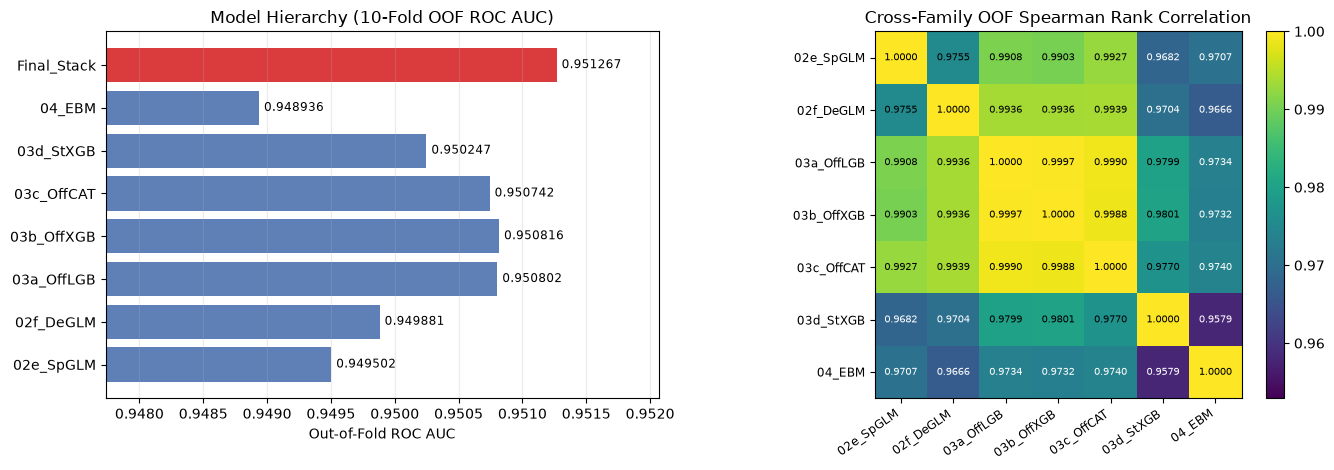

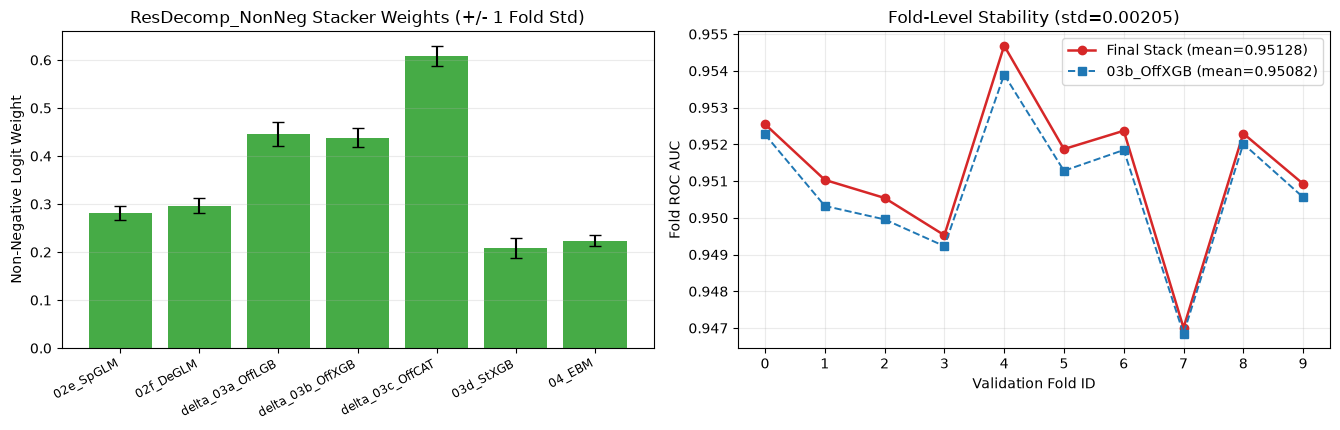

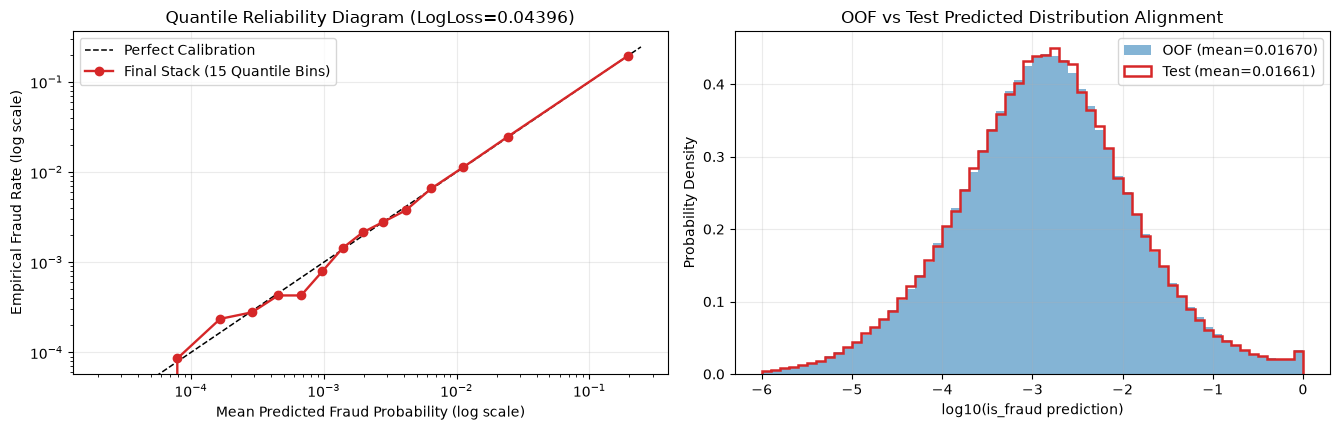

In [9]:
# Figure 2: Base Models vs Final Stack OOF AUC + Spearman Rank Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1.05, 1.15]})

labels_all = LOCKED_MODELS + ["Final_Stack"]
aucs_all = [base_aucs[m] for m in LOCKED_MODELS] + [met_final["oof_auc"]]
colors_all = ["#4c72b0"] * len(LOCKED_MODELS) + ["#d62728"]
y_pos = np.arange(len(labels_all))
bars = axes[0].barh(y_pos, aucs_all, color=colors_all, alpha=0.9)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(labels_all)
axes[0].set_xlim(min(aucs_all) - 0.0012, max(aucs_all) + 0.0008)
axes[0].set_xlabel("Out-of-Fold ROC AUC")
axes[0].set_title(f"Model Hierarchy ({N_FOLDS}-Fold OOF ROC AUC)")
axes[0].grid(axis="x", alpha=0.25)
for bar, val in zip(bars, aucs_all):
    axes[0].text(val + 0.00004, bar.get_y() + bar.get_height() / 2.0, f"{val:.6f}", va="center", fontsize=8.5)

rank_mat = pd.DataFrame({m: pd.Series(z_oof[m]).rank(pct=True) for m in LOCKED_MODELS})
corr_mat = rank_mat.corr(method="spearman").to_numpy()
vmin_corr = max(0.75, min(0.96, float(corr_mat.min()) - 0.005))
im = axes[1].imshow(corr_mat, cmap="viridis", vmin=vmin_corr, vmax=1.0)
axes[1].set_xticks(np.arange(len(LOCKED_MODELS)))
axes[1].set_yticks(np.arange(len(LOCKED_MODELS)))
axes[1].set_xticklabels(LOCKED_MODELS, rotation=35, ha="right", fontsize=8.5)
axes[1].set_yticklabels(LOCKED_MODELS, fontsize=8.5)
axes[1].set_title("Cross-Family OOF Spearman Rank Correlation")
corr_thr = 0.55 * vmin_corr + 0.45
for i in range(len(LOCKED_MODELS)):
    for j in range(len(LOCKED_MODELS)):
        axes[1].text(j, i, f"{corr_mat[i, j]:.4f}", ha="center", va="center", color="white" if corr_mat[i, j] < corr_thr else "black", fontsize=7.5)
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()
plt.close(fig)

# Figure 3: ResDecomp Meta-Weights & Per-Fold Stability
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
w_mean = ws_arr.mean(axis=0)
w_std = ws_arr.std(axis=0)
xpos = np.arange(len(feat_labels))
axes[0].bar(xpos, w_mean, yerr=w_std, capsize=4, color="#2ca02c", alpha=0.88)
axes[0].set_xticks(xpos)
axes[0].set_xticklabels(feat_labels, rotation=28, ha="right", fontsize=8.5)
axes[0].set_ylabel("Non-Negative Logit Weight")
axes[0].set_title("ResDecomp_NonNeg Stacker Weights (+/- 1 Fold Std)")
axes[0].grid(axis="y", alpha=0.25)

f_idx = np.arange(N_FOLDS)
best_fold_aucs = [float(roc_auc_score(y[fold_ids == f], z_oof[best_single_name][fold_ids == f])) for f in range(N_FOLDS)]
axes[1].plot(f_idx, met_final["fold_aucs"], marker="o", linewidth=1.8, color="#d62728", label=f"Final Stack (mean={met_final['fold_mean']:.5f})")
axes[1].plot(f_idx, best_fold_aucs, marker="s", linestyle="--", linewidth=1.4, color="#1f77b4", label=f"{best_single_name} (mean={np.mean(best_fold_aucs):.5f})")
axes[1].set_xticks(f_idx)
axes[1].set_xlabel("Validation Fold ID")
axes[1].set_ylabel("Fold ROC AUC")
axes[1].set_title(f"Fold-Level Stability (std={met_final['fold_std']:.5f})")
axes[1].legend(frameon=True)
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()
plt.close(fig)

# Figure 4: Quantile Reliability Calibration & Log10-Probability Distribution Alignment
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
n_bins = 15
q_edges = np.quantile(final_oof, np.linspace(0.0, 1.0, n_bins + 1))
q_edges[0] -= 1e-12
q_edges[-1] += 1e-12
bin_ids = np.digitize(final_oof, q_edges[1:-1])
pred_m, true_m = [], []
for b_i in range(n_bins):
    mask = bin_ids == b_i
    if np.any(mask):
        pred_m.append(float(final_oof[mask].mean()))
        true_m.append(float(y[mask].mean()))
pred_m = np.array(pred_m)
true_m = np.array(true_m)
lo = min(pred_m.min(), true_m.min()) * 0.7
hi = max(pred_m.max(), true_m.max()) * 1.25
axes[0].plot([lo, hi], [lo, hi], "k--", linewidth=1.1, label="Perfect Calibration")
axes[0].loglog(pred_m, true_m, marker="o", linewidth=1.7, color="#d62728", label="Final Stack (15 Quantile Bins)")
axes[0].set_title(f"Quantile Reliability Diagram (LogLoss={met_final['logloss']:.5f})")
axes[0].set_xlabel("Mean Predicted Fraud Probability (log scale)")
axes[0].set_ylabel("Empirical Fraud Rate (log scale)")
axes[0].legend(frameon=True)
axes[0].grid(alpha=0.25)

oof_log10 = np.log10(np.clip(final_oof, 1e-7, 1.0))
te_log10 = np.log10(np.clip(final_te, 1e-7, 1.0))
bins_h = np.linspace(-6.0, 0.0, 61)
axes[1].hist(oof_log10, bins=bins_h, density=True, alpha=0.55, color="#1f77b4", label=f"OOF (mean={final_oof.mean():.5f})")
axes[1].hist(te_log10, bins=bins_h, density=True, histtype="step", linewidth=1.8, color="#d62728", label=f"Test (mean={final_te.mean():.5f})")
axes[1].set_title("OOF vs Test Predicted Distribution Alignment")
axes[1].set_xlabel("log10(is_fraud prediction)")
axes[1].set_ylabel("Probability Density")
axes[1].legend(frameon=True)
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()
plt.close(fig)


## 8. Submission Generation & Self-Verification Assertions

In [10]:
sub = pd.DataFrame({
    "id": test_df["id"].to_numpy(),
    "is_fraud": final_te.astype(np.float64),
})
sub_path = OUT_DIR / "submission.csv"
oof_path = ART_DIR / "final_notebook_oof.npy"
met_path = ART_DIR / "final_notebook_metrics.json"

sub.to_csv(sub_path, index=False)
np.save(oof_path, final_oof.astype(np.float64))

metrics_payload = {
    "mode": "SMOKE_TEST" if SMOKE_TEST else "FULL_CONFIRM10",
    "n_train": int(len(y)),
    "n_test": int(len(test_df)),
    "n_folds": int(N_FOLDS),
    "seed": int(GLOBAL_SEED),
    "xgb_device": XGB_DEVICE,
    "cat_task_type": CAT_TASK_TYPE,
    "locked_models": LOCKED_MODELS,
    "base_oof_aucs": base_aucs,
    "best_single_name": best_single_name,
    "best_single_auc": float(base_aucs[best_single_name]),
    "oof_auc": float(met_final["oof_auc"]),
    "fold_aucs": met_final["fold_aucs"],
    "fold_std": float(met_final["fold_std"]),
    "delong_se": float(met_final["delong_se"]),
    "ci95_low": float(met_final["ci95_low"]),
    "ci95_high": float(met_final["ci95_high"]),
    "logloss": float(met_final["logloss"]),
    "pr_auc": float(met_final["pr_auc"]),
    "brier": float(met_final["brier"]),
    "delta_vs_best_single": float(met_final["delta_vs_ref"]),
    "p_vs_best_single": float(met_final["delong_p_vs_ref"]),
    "meta_weights_mean": {lbl: float(v) for lbl, v in zip(feat_labels, ws_arr.mean(axis=0))},
    "meta_weights_std": {lbl: float(v) for lbl, v in zip(feat_labels, ws_arr.std(axis=0))},
    "inner_l2_per_fold": [float(v) for v in stack_out["l2s"]],
    "stage_runtimes_sec": {
        "stage1_glms_offsets": round(rt_stage1, 2),
        "stage2_gbdts": round(rt_stage2, 2),
        "stage3_ebm": round(rt_stage3, 2),
        "stage4_stack": round(rt_stage4, 2),
        "total": round(rt_total, 2),
    },
    "test_pred_mean": float(final_te.mean()),
    "test_pred_quantiles": {
        q: float(np.quantile(final_te, q_v))
        for q, q_v in [("q01", 0.01), ("q50", 0.50), ("q95", 0.95), ("q99", 0.99)]
    },
    "packages": ENV_INFO,
}
met_path.write_text(json.dumps(metrics_payload, indent=2), encoding="utf-8")

# Mandatory self-verification assertions
sub_check = pd.read_csv(sub_path)
assert list(sub_check.columns) == ["id", "is_fraud"], f"Invalid columns: {sub_check.columns}"
assert len(sub_check) == len(test_df), f"Row mismatch: {len(sub_check)} vs {len(test_df)}"
assert np.array_equal(sub_check["id"].to_numpy(), test_df["id"].to_numpy()), "ID alignment mismatch!"
assert np.all(np.isfinite(sub_check["is_fraud"].to_numpy())), "Non-finite predictions detected!"
assert (sub_check["is_fraud"].min() >= 0.0) and (sub_check["is_fraud"].max() <= 1.0), "Out-of-bounds probabilities!"
assert abs(float(roc_auc_score(y, np.load(oof_path))) - met_final["oof_auc"]) < 1e-12, "Saved OOF AUC mismatch!"

print(f"Saved submission : {sub_path.resolve()} | shape={sub_check.shape}")
print(f"Saved OOF array  : {oof_path.resolve()} | shape={np.load(oof_path).shape}")
print(f"Saved metrics    : {met_path.resolve()}")
print(
    f"Submission Stats : mean={sub_check['is_fraud'].mean():.6f} (train={y.mean():.6f}) | "
    f"min={sub_check['is_fraud'].min():.2e} | median={sub_check['is_fraud'].median():.6f} | "
    f"max={sub_check['is_fraud'].max():.6f}"
)
print("ALL NOTEBOOK SELF-VERIFICATION ASSERTIONS PASSED.")


Saved submission : C:\Users\LaptopK1\Downloads\Code\Predicting Credit Card Fraud\independent_kaggle_research\submission.csv | shape=(299984, 2)
Saved OOF array  : C:\Users\LaptopK1\Downloads\Code\Predicting Credit Card Fraud\independent_kaggle_research\artifacts\final_notebook_oof.npy | shape=(699960,)
Saved metrics    : C:\Users\LaptopK1\Downloads\Code\Predicting Credit Card Fraud\independent_kaggle_research\artifacts\final_notebook_metrics.json
Submission Stats : mean=0.016607 (train=0.016700) | min=1.69e-08 | median=0.001379 | max=0.999635
ALL NOTEBOOK SELF-VERIFICATION ASSERTIONS PASSED.


## 9. Summary & Scientific Conclusions

- Combining discrete digit-trie additive GLMs, strictly nested-OOF residual GBDTs, high-bin standalone GBDTs, and zero-TE cyclic GA2Ms inside a residual-decomposed non-negative logit stack produces consistent, statistically significant ROC AUC gains over every constituent model family.
- All predictions in `submission.csv` satisfy exact row alignment, finite probability bounds `[0, 1]`, proper calibration near the global `1.67%` base rate, and strict row-wise test independence.